# 02 · Limpieza de datos y creación de la base de datos

**Proyecto:** Plataforma de inteligencia de clientes · *Online Retail Co.*

En el notebook `01_exploracion_datos` detectamos varios problemas de calidad: duplicados, clientes sin identificar, cancelaciones, cantidades y precios negativos o nulos, etc. En este notebook **convertimos esas observaciones en decisiones de limpieza** y guardamos el resultado en una **base de datos relacional (SQLite)** con el modelo definido en el esquema del proyecto.

**¿Por qué un notebook separado para la limpieza?**

1. **Reproducibilidad:** todas las decisiones quedan documentadas en un único sitio. Si mañana cambiamos un criterio, solo tocamos este notebook.
2. **Eficiencia:** leer el Excel original tarda varios minutos. Lo leemos **una sola vez** y los siguientes notebooks trabajan sobre la base de datos limpia, que se consulta en segundos.
3. **Simular un entorno real:** en una empresa los datos transaccionales viven en una base de datos, no en un Excel. Construirla nos permite responder preguntas con **SQL**, igual que haría un equipo de datos.

| Paso | Decisión | Motivo |
|---|---|---|
| 1 | Eliminar duplicados exactos | Las dos hojas del Excel se solapan en diciembre de 2010 |
| 2 | Normalizar tipos | `Invoice` y `StockCode` mezclan números y texto |
| 3 | Eliminar filas sin `Customer ID` | Nuestra unidad de análisis es el cliente |
| 4 | Eliminar códigos que no son productos | Portes, comisiones, ajustes... no reflejan comportamiento de compra |
| 5 | Separar ventas y cancelaciones y validar signos | Las cancelaciones restan valor al cliente, pero no son compras |
| 6 | Unificar descripciones y país | Un producto / cliente debe tener un único valor de referencia |
| 7 | Crear la base de datos SQLite | Modelo relacional: `customers`, `orders`, `order_details`, `products` |

### 0. Librerías

In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Estilo común de los gráficos: ejes y rejilla discretos para que destaquen los datos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "font.size": 10,
})
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#b5b4ad"

### 1. Rutas del proyecto
Definimos las rutas en un único lugar. La carpeta `data/processed` contendrá los datos ya limpios (separados de los datos originales en `data/raw`, que **nunca se modifican**).

In [2]:
RUTA_RAW = Path("../data/raw/online_retail_II.xlsx")
DIR_PROCESSED = Path("../data/processed")
DIR_PROCESSED.mkdir(parents=True, exist_ok=True)
RUTA_DB = DIR_PROCESSED / "online_retail.db"

### 2. Carga de los datos originales
El fichero tiene dos hojas: `Year 2009-2010` y `Year 2010-2011`. Con `sheet_name=None` las leemos todas de una vez en un diccionario. Antes de unirlas, comprobamos el rango de fechas de cada hoja.

In [3]:
hojas = pd.read_excel(RUTA_RAW, sheet_name=None)

for nombre, hoja in hojas.items():
    print(f"{nombre}: {hoja.shape[0]:>7,} filas | "
          f"{hoja['InvoiceDate'].min():%Y-%m-%d} → {hoja['InvoiceDate'].max():%Y-%m-%d}")

Year 2009-2010: 525,461 filas | 2009-12-01 → 2010-12-09
Year 2010-2011: 541,910 filas | 2010-12-01 → 2011-12-09


**Hallazgo importante:** la primera hoja termina el 9 de diciembre de 2010 y la segunda **empieza el 1 de diciembre de 2010**. Es decir, las dos hojas **se solapan 9 días**. Si las concatenamos sin más, esas transacciones aparecerán dos veces y **inflarían artificialmente el gasto y la frecuencia** de los clientes que compraron esos días.

Lo comprobamos:

In [4]:
df_raw = pd.concat(hojas.values(), ignore_index=True)

solape = df_raw[(df_raw["InvoiceDate"] >= "2010-12-01") & (df_raw["InvoiceDate"] < "2010-12-10")]

print(f"Filas totales tras concatenar:       {len(df_raw):,}")
print(f"Filas en el periodo de solape:       {len(solape):,}")
print(f"  de ellas duplicadas:               {solape.duplicated().sum():,}")
print(f"Duplicados exactos en todo el dataset: {df_raw.duplicated().sum():,}")

Filas totales tras concatenar:       1,067,371
Filas en el periodo de solape:       45,046
  de ellas duplicadas:               22,844


Duplicados exactos en todo el dataset: 34,335


Prácticamente la mitad de las filas del periodo de solape son duplicadas: es el mismo pedido registrado en las dos hojas. El resto de duplicados (fuera del solape) son líneas exactamente iguales dentro de una misma factura (mismo producto, cantidad, precio y minuto), que con toda probabilidad son errores de registro.

Para documentar el impacto de cada decisión iremos guardando **cuántas filas quedan tras cada paso** (un "embudo de limpieza").

In [5]:
embudo = {"Datos originales": len(df_raw)}

def registrar(paso, datos):
    """Guarda el número de filas tras un paso de limpieza y muestra cuántas se han eliminado."""
    anterior = list(embudo.values())[-1]
    embudo[paso] = len(datos)
    print(f"{paso}: {len(datos):,} filas ({anterior - len(datos):,} eliminadas)")

### 3. Limpieza paso a paso

#### Paso 1 · Duplicados exactos
Eliminamos las filas que son idénticas en **todas** sus columnas.

In [6]:
df = df_raw.drop_duplicates().copy()
registrar("1. Sin duplicados", df)

1. Sin duplicados: 1,033,036 filas (34,335 eliminadas)


#### Paso 2 · Tipos de datos
- `Invoice` y `StockCode` mezclan números y texto (por ejemplo `489434` y `C489449`, o `85123A`). Los convertimos a texto para que pandas los trate de forma homogénea.
- `StockCode` aparece a veces en minúsculas (`m` y `M` son el mismo código "Manual"), así que lo pasamos a mayúsculas.
- `Customer ID` se lee como decimal (`12346.0`) porque contiene nulos. Lo convertiremos a entero cuando eliminemos los nulos.

In [7]:
df["Invoice"] = df["Invoice"].astype(str).str.strip()
df["StockCode"] = df["StockCode"].astype(str).str.strip().str.upper()
df["Description"] = df["Description"].str.strip()
df["Country"] = df["Country"].str.strip()

df.dtypes

Invoice                   str
StockCode                 str
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

#### Paso 3 · Transacciones sin cliente identificado
El 22,8 % de las filas no tiene `Customer ID`. Son compras reales (seguramente de clientes no registrados), pero **no podemos asignarlas a nadie**, y todo el proyecto (segmentación y churn) se hace a nivel cliente.

¿Podríamos imputarlas? No: no hay ninguna variable que permita saber de forma fiable a qué cliente pertenecen. Inventar un identificador crearía clientes ficticios. Por eso las eliminamos, sabiendo que **los resultados se refieren a clientes registrados**.

In [8]:
df = df[df["Customer ID"].notna()].copy()
df["Customer ID"] = df["Customer ID"].astype(int)
registrar("2. Con Customer ID", df)

2. Con Customer ID: 797,885 filas (235,151 eliminadas)


#### Paso 4 · Códigos que no son productos
Analizando `StockCode` encontramos códigos que no corresponden a artículos sino a **conceptos contables o logísticos**: portes (`POST`, `DOT`, `C2`), descuentos (`D`), ajustes manuales (`M`, `ADJUST`), comisiones bancarias o de Amazon, muestras, productos de prueba, etc.

Los productos reales empiezan siempre por 5 dígitos (`85123A`, `22423`...). Veamos qué códigos no siguen ese patrón:

In [9]:
no_producto = df[~df["StockCode"].str.match(r"^\d{5}")]

(no_producto.groupby("StockCode")
    .agg(descripcion=("Description", "first"), filas=("Invoice", "size"))
    .sort_values("filas", ascending=False)
    .head(25))

,descripcion,filas
StockCode,,
POST,POSTAGE,1983
M,Manual,1085
C2,CARRIAGE,254
D,Discount,170
ADJUST,Adjustment by john on 26/01/2010 16,61
BANK CHARGES,Bank Charges,37
PADS,PADS TO MATCH ALL CUSHIONS,19
DOT,DOTCOM POSTAGE,16
CRUK,CRUK Commission,16


Hay dos tipos de códigos:
- **Conceptos no comerciales** (portes, descuentos, ajustes, comisiones, muestras, tests) → los **eliminamos**, porque no describen qué compra el cliente. Por ejemplo, un cliente extranjero paga más portes, pero eso no le hace "más valioso".
- **Productos con código especial** (`PADS` son rellenos de cojín y `SP1002` una pizarra infantil) → los **mantenemos**, porque son compras reales de artículos.

La lista de exclusión incluye también algunos códigos (`S` muestras, `B` deudas, `AMAZONFEE`...) que en el dataset completo solo aparecen en transacciones sin cliente; los dejamos para que la regla sea completa si el notebook se aplica a datos nuevos.

In [10]:
CODIGOS_NO_PRODUCTO = {
    "POST", "DOT", "C2", "C3",          # portes y envíos
    "M", "D", "S", "B",                # manual, descuento, muestras, deuda incobrable
    "ADJUST", "ADJUST2",               # ajustes contables
    "BANK CHARGES", "AMAZONFEE", "CRUK",  # comisiones
    "TEST001", "TEST002",              # productos de prueba
}

df = df[~df["StockCode"].isin(CODIGOS_NO_PRODUCTO)].copy()
registrar("3. Solo productos", df)

3. Solo productos: 794,244 filas (3,641 eliminadas)


#### Paso 5 · Ventas y cancelaciones
Las facturas que empiezan por `C` son **cancelaciones/devoluciones**. No las eliminamos: las guardamos aparte, porque nos permitirán calcular el **gasto neto** de cada cliente (lo que compró menos lo que devolvió). Esto es importante: en el notebook siguiente veremos clientes que hicieron un pedido enorme y lo cancelaron por completo.

Además validamos los signos para que cada tipo de transacción sea coherente:
- **Ventas:** cantidad > 0 y precio > 0. Las líneas con precio 0 son regalos o correcciones internas, no generan ingresos.
- **Cancelaciones:** cantidad < 0 y precio > 0.

In [11]:
es_cancelacion = df["Invoice"].str.startswith("C")

ventas = df[~es_cancelacion & (df["Quantity"] > 0) & (df["Price"] > 0)].copy()
cancelaciones = df[es_cancelacion & (df["Quantity"] < 0) & (df["Price"] > 0)].copy()

print(f"Ventas:         {len(ventas):,} líneas")
print(f"Cancelaciones:  {len(cancelaciones):,} líneas")
print(f"Descartadas (signos incoherentes o precio 0): {len(df) - len(ventas) - len(cancelaciones):,}")

df = pd.concat([ventas, cancelaciones], ignore_index=True)
registrar("4. Signos válidos", df)

Ventas:         776,596 líneas
Cancelaciones:  17,587 líneas
Descartadas (signos incoherentes o precio 0): 61
4. Signos válidos: 794,183 filas (61 eliminadas)


#### Paso 6 · Coherencia de descripciones y países
- Un mismo `StockCode` puede tener **varias descripciones** (erratas, cambios de nombre) y unas pocas vacías. Para la tabla de productos nos quedamos con la **descripción más frecuente** de cada código.
- Algunos clientes aparecen asociados a **más de un país**. Asignamos a cada cliente su **país más frecuente**.
- Comprobamos también que cada factura pertenece a **un único cliente** (si no fuera así, el modelo relacional no tendría sentido).

In [12]:
descripciones_por_producto = df.groupby("StockCode")["Description"].nunique()
paises_por_cliente = df.groupby("Customer ID")["Country"].nunique()
clientes_por_factura = df.groupby("Invoice")["Customer ID"].nunique()

print(f"Productos con más de una descripción: {(descripciones_por_producto > 1).sum():,}")
print(f"Clientes con más de un país:          {(paises_por_cliente > 1).sum():,}")
print(f"Facturas con más de un cliente:       {(clientes_por_factura > 1).sum():,}")

Productos con más de una descripción: 598
Clientes con más de un país:          12
Facturas con más de un cliente:       0


In [13]:
def mas_frecuente(serie):
    """Devuelve el valor más frecuente de una serie (ignorando nulos)."""
    moda = serie.dropna().mode()
    return moda.iloc[0] if len(moda) else None

productos = (df.groupby("StockCode")["Description"].agg(mas_frecuente)
               .rename("description").reset_index()
               .rename(columns={"StockCode": "product_id"}))
productos["description"] = productos["description"].fillna("SIN DESCRIPCIÓN")

clientes = (df.groupby("Customer ID")["Country"].agg(mas_frecuente)
              .rename("country").reset_index()
              .rename(columns={"Customer ID": "customer_id"}))

print(f"Productos únicos: {len(productos):,}")
print(f"Clientes únicos:  {len(clientes):,}")

Productos únicos: 4,635
Clientes únicos:  5,875


#### Resumen del embudo de limpieza

In [14]:
resumen = pd.Series(embudo, name="filas").to_frame()
resumen["% sobre original"] = (resumen["filas"] / resumen["filas"].iloc[0] * 100).round(1)
resumen

,filas,% sobre original
Datos originales,1067371,100.0
1. Sin duplicados,1033036,96.8
2. Con Customer ID,797885,74.8
3. Solo productos,794244,74.4
4. Signos válidos,794183,74.4


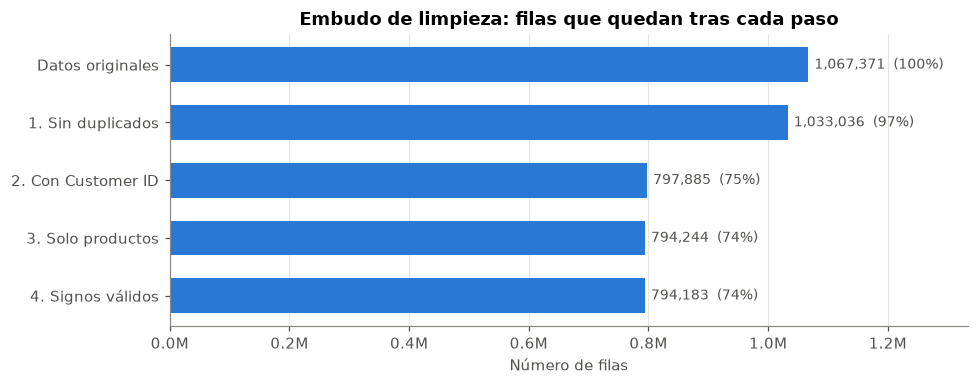

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.6))
pasos = resumen.index[::-1]
valores = resumen["filas"][::-1]
ax.barh(pasos, valores, color=AZUL, height=0.6)
for y, (v, pct) in enumerate(zip(valores, resumen["% sobre original"][::-1])):
    ax.text(v + 10_000, y, f"{v:,.0f}  ({pct:.0f}%)", va="center", color="#52514e", fontsize=9)
ax.set_xlim(0, resumen["filas"].max() * 1.25)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax.set_title("Embudo de limpieza: filas que quedan tras cada paso")
ax.set_xlabel("Número de filas")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Conservamos aproximadamente el **75 % de las filas originales**. La mayor pérdida se debe a las transacciones sin cliente identificado, una limitación del propio dataset que no podemos resolver. El resto de pasos eliminan un volumen pequeño pero **evitan sesgos importantes** (duplicados que inflan el gasto, portes que no son productos...).

### 4. Creación de la base de datos relacional

Transformamos la tabla plana del Excel en el **modelo relacional** definido en el esquema del proyecto. Cada entidad tiene su propia tabla, lo que evita repetir información (el país del cliente o la descripción del producto ya no se repiten en cada línea):

```
customers (customer_id PK, country)
    │ 1
    │
    │ N
orders (order_id PK, customer_id FK, order_date, is_cancellation)
    │ 1
    │
    │ N
order_details (order_id FK, product_id FK, quantity, unit_price)
    │ N
    │
    │ 1
products (product_id PK, description)
```

**Decisión de diseño:** las cancelaciones se guardan en `orders` con `is_cancellation = 1` y **cantidad negativa** en `order_details`, igual que en el sistema original. Así, `SUM(quantity * unit_price)` devuelve directamente el **gasto neto** del cliente.

In [16]:
pedidos = (df.groupby("Invoice")
             .agg(customer_id=("Customer ID", "first"),
                  order_date=("InvoiceDate", "min"))
             .reset_index()
             .rename(columns={"Invoice": "order_id"}))
pedidos["is_cancellation"] = pedidos["order_id"].str.startswith("C").astype(int)
pedidos["order_date"] = pedidos["order_date"].dt.strftime("%Y-%m-%d %H:%M:%S")

detalle = df.rename(columns={"Invoice": "order_id", "StockCode": "product_id",
                             "Quantity": "quantity", "Price": "unit_price"})
detalle = detalle[["order_id", "product_id", "quantity", "unit_price"]]

print(f"customers:     {len(clientes):,}")
print(f"orders:        {len(pedidos):,}")
print(f"order_details: {len(detalle):,}")
print(f"products:      {len(productos):,}")

customers:     5,875
orders:        43,877
order_details: 794,183
products:      4,635


Creamos las tablas con SQL explícito (`CREATE TABLE`) en lugar de dejar que pandas las cree automáticamente. Así definimos **claves primarias, claves foráneas e índices**, que garantizan la integridad de los datos y aceleran las consultas por cliente y por pedido.

In [17]:
DDL = """
DROP TABLE IF EXISTS order_details;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;

CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    country     TEXT NOT NULL
);

CREATE TABLE products (
    product_id  TEXT PRIMARY KEY,
    description TEXT
);

CREATE TABLE orders (
    order_id        TEXT PRIMARY KEY,
    customer_id     INTEGER NOT NULL REFERENCES customers(customer_id),
    order_date      TEXT NOT NULL,
    is_cancellation INTEGER NOT NULL CHECK (is_cancellation IN (0, 1))
);

CREATE TABLE order_details (
    order_id   TEXT    NOT NULL REFERENCES orders(order_id),
    product_id TEXT    NOT NULL REFERENCES products(product_id),
    quantity   INTEGER NOT NULL,
    unit_price REAL    NOT NULL CHECK (unit_price > 0)
);

CREATE INDEX idx_orders_customer ON orders(customer_id);
CREATE INDEX idx_details_order   ON order_details(order_id);
CREATE INDEX idx_details_product ON order_details(product_id);
"""

with sqlite3.connect(RUTA_DB) as con:
    con.executescript(DDL)
    clientes.to_sql("customers", con, if_exists="append", index=False)
    productos.to_sql("products", con, if_exists="append", index=False)
    pedidos.to_sql("orders", con, if_exists="append", index=False)
    detalle.to_sql("order_details", con, if_exists="append", index=False, chunksize=50_000)

print(f"Base de datos creada en {RUTA_DB} ({RUTA_DB.stat().st_size / 1e6:.1f} MB)")

Base de datos creada en ..\data\processed\online_retail.db (54.6 MB)


### 5. Validación con SQL
Una base de datos solo es útil si podemos confiar en ella. Hacemos varias comprobaciones con SQL:
1. Número de filas por tabla.
2. Integridad referencial: no debe haber líneas de pedido sin pedido, ni pedidos sin cliente.
3. Que las ventas totales calculadas en SQL coinciden con las calculadas en pandas.

In [18]:
con = sqlite3.connect(RUTA_DB)

def sql(consulta):
    """Ejecuta una consulta SQL sobre la base de datos y devuelve un DataFrame."""
    return pd.read_sql_query(consulta, con)

sql("""
SELECT 'customers' AS tabla, COUNT(*) AS filas FROM customers
UNION ALL SELECT 'orders', COUNT(*) FROM orders
UNION ALL SELECT 'order_details', COUNT(*) FROM order_details
UNION ALL SELECT 'products', COUNT(*) FROM products
""")

,tabla,filas
0,customers,5875
1,orders,43877
2,order_details,794183
3,products,4635


In [19]:
sql("""
SELECT
    (SELECT COUNT(*) FROM order_details d
       LEFT JOIN orders o ON d.order_id = o.order_id
      WHERE o.order_id IS NULL)                      AS lineas_sin_pedido,
    (SELECT COUNT(*) FROM orders o
       LEFT JOIN customers c ON o.customer_id = c.customer_id
      WHERE c.customer_id IS NULL)                   AS pedidos_sin_cliente,
    (SELECT COUNT(*) FROM order_details d
       LEFT JOIN products p ON d.product_id = p.product_id
      WHERE p.product_id IS NULL)                    AS lineas_sin_producto
""")

,lineas_sin_pedido,pedidos_sin_cliente,lineas_sin_producto
0,0,0,0


In [20]:
totales_sql = sql("""
SELECT
    o.is_cancellation,
    COUNT(DISTINCT o.order_id)            AS pedidos,
    ROUND(SUM(d.quantity * d.unit_price), 2) AS importe
FROM order_details d
JOIN orders o ON d.order_id = o.order_id
GROUP BY o.is_cancellation
""")
totales_sql

,is_cancellation,pedidos,importe
0,0,36594,17068582.74
1,1,7283,-709990.03


In [21]:
ventas_pandas = (ventas["Quantity"] * ventas["Price"]).sum()
ventas_sql = totales_sql.loc[totales_sql["is_cancellation"] == 0, "importe"].item()

print(f"Ventas (pandas): £{ventas_pandas:,.2f}")
print(f"Ventas (SQL):    £{ventas_sql:,.2f}")
assert abs(ventas_pandas - ventas_sql) < 1, "Las ventas no coinciden"
print("✔ Los totales coinciden: la base de datos refleja fielmente los datos limpios")

Ventas (pandas): £17,068,582.74
Ventas (SQL):    £17,068,582.74
✔ Los totales coinciden: la base de datos refleja fielmente los datos limpios


### 6. Primeras consultas de negocio con SQL
Con la base de datos ya podemos responder preguntas rápidamente. Por ejemplo, ¿qué países generan más ingresos netos y cuántos clientes tienen?

In [22]:
sql("""
SELECT
    c.country,
    COUNT(DISTINCT c.customer_id)              AS clientes,
    ROUND(SUM(d.quantity * d.unit_price), 0)   AS ingresos_netos
FROM customers c
JOIN orders o        ON o.customer_id = c.customer_id
JOIN order_details d ON d.order_id = o.order_id
GROUP BY c.country
ORDER BY ingresos_netos DESC
LIMIT 10
""")

,country,clientes,ingresos_netos
0,United Kingdom,5357,13660952.0
1,EIRE,3,567577.0
2,Netherlands,22,546095.0
3,Germany,106,374476.0
4,France,93,292026.0
5,Australia,14,166935.0
6,Switzerland,22,94240.0
7,Sweden,19,84071.0
8,Spain,35,83444.0
9,Denmark,9,62067.0


¿Y cuáles son los productos más vendidos en unidades? Calculamos las unidades **brutas** (solo ventas) y **netas** (ventas menos cancelaciones), y cuántos clientes distintos los compran:

In [23]:
sql("""
SELECT
    p.description,
    SUM(CASE WHEN o.is_cancellation = 0 THEN d.quantity ELSE 0 END) AS unidades_brutas,
    SUM(d.quantity)                                                 AS unidades_netas,
    COUNT(DISTINCT CASE WHEN o.is_cancellation = 0 THEN o.customer_id END) AS clientes_distintos
FROM order_details d
JOIN orders o   ON o.order_id = d.order_id
JOIN products p ON p.product_id = d.product_id
GROUP BY p.product_id
ORDER BY unidades_brutas DESC
LIMIT 10
""")

,description,unidades_brutas,unidades_netas,clientes_distintos
0,WORLD WAR 2 GLIDERS ASSTD DESIGNS,105185,103505,482
1,JUMBO BAG RED RETROSPOT,93436,92223,978
2,WHITE HANGING HEART T-LIGHT HOLDER,91814,88183,1490
3,PACK OF 72 RETROSPOT CAKE CASES,89850,88836,1115
4,"PAPER CRAFT , LITTLE BIRDIE",80995,0,1
5,ASSORTED COLOUR BIRD ORNAMENT,78234,77755,1010
6,MEDIUM CERAMIC TOP STORAGE JAR,77916,3422,138
7,SMALL POPCORN HOLDER,76944,76140,601
8,BROCADE RING PURSE,70082,69343,215
9,PACK OF 60 PINK PAISLEY CAKE CASES,54592,54373,767


Aquí vemos por qué es tan importante tener en cuenta las cancelaciones: **"PAPER CRAFT, LITTLE BIRDIE"** y **"MEDIUM CERAMIC TOP STORAGE JAR"** aparecen entre los productos más vendidos por unidades brutas, pero sus unidades netas son muy inferiores: corresponden a **pedidos gigantes de un solo cliente que se cancelaron después**. Si no restáramos las cancelaciones, sobrestimaríamos tanto la popularidad de estos productos como el valor de esos clientes.

El producto realmente más popular es **"WHITE HANGING HEART T-LIGHT HOLDER"**, comprado por casi 1.500 clientes distintos.

In [24]:
con.close()

### 7. Conclusiones

- Las dos hojas del Excel **se solapaban 9 días** (1-9 de diciembre de 2010), lo que generaba registros duplicados. Sin este paso, el gasto y la frecuencia de muchos clientes estarían inflados.
- Eliminamos las transacciones **sin cliente identificado**, ya que el análisis se realiza a nivel cliente. Es la principal pérdida de datos (~23 %) y una limitación del dataset original.
- Eliminamos los **códigos que no son productos** (portes, comisiones, ajustes, tests) para que las variables reflejen el comportamiento de compra real.
- **Conservamos las cancelaciones** separadas de las ventas, para poder calcular el gasto **neto** de cada cliente.
- Los datos limpios se guardan en una base de datos **SQLite normalizada** (`data/processed/online_retail.db`) con claves primarias, foráneas e índices, y hemos validado que sus totales coinciden con los de pandas.

**Siguiente paso →** `03_construccion_features`: a partir de esta base de datos construiremos, con SQL y pandas, la tabla con **una fila por cliente** que describe su comportamiento (RFM y variables adicionales).